## Fault motion analysis from InSAR ground motion data

Analyze the current behaviour of normal faults by checking if the trends on averaged time series over polygons outlining the footwall and hanging wall are statistically different or identical. \
This code only screens InSAR ground motion data, which may contain non-tectonic signals. Assuming only tectonic signals are recorded, statistically different trends may indicate a fault is unlocked and experiencing aseismic (transient or steady) or coseismic (earthquake) slip during the time period of the InSAR data input. \
**Work in progress!**


To run: 
* Download EGMS vertical data (check below for the releases used here)
* Adapt the paths to your repository and run this notebook. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from shapely.geometry import Polygon
from matplotlib.lines import Line2D

import modules.dataloader as dl
from FaultAnalyzer import FaultPolygons, PolygonTS, TrendPValues
from modules.plotting import HandlerBlackWhiteDashed

### 1. Read fault and map data

In [2]:
sm_faults_gdf = dl.load_faults_gdf('data/faults/sam_mitchell_faults.kml')
sm_faults_dict = dl.load_faults_as_dict('data/faults/sam_mitchell_faults.kml')

DEFAULT CRS: EPSG:4326
DEFAULT CRS: EPSG:4326


In [3]:
greece = dl.load_world_data()
greece = greece[greece.gridcode==0]

### 2. Load EGMS data (run only once)

* Part A saves EGMS squares into bands, which will be used to calculate time series around faults.
* Part B only loads the bands, in case these have been calculated before. 

-> Run both if running the analysis for the first time. \
-> Run only B if the bands have already been saved and you want to generate time series around faults. \
-> Run none and proceed to next point if only evaluating already-calculated time series. 

#### A. Save EGMS data over Greece into bands 
The four overlapping bands ensure no faults are "in between" two datasets and contribute to lowering runtime. **Run this only once to save the EGMS data into new files, then just read them in as in the next section.** This may take a few minutes to run. 

In [4]:
# egms_E53N17 = dl.load_egms_df('data/egms/EGMS_L3_E53N17_100km_U_2019_2023_1.csv')
# egms_E54N17 = dl.load_egms_df('data/egms/EGMS_L3_E54N17_100km_U_2019_2023_1.csv')
# egms_E55N17 = dl.load_egms_df('data/egms/EGMS_L3_E55N17_100km_U_2019_2023_1.csv')

In [5]:
# egms_E53N18 = dl.load_egms_df('data/egms/EGMS_L3_E53N18_100km_U_2019_2023_1.csv')
# egms_E54N18 = dl.load_egms_df('data/egms/EGMS_L3_E54N18_100km_U_2019_2023_1.csv')
# egms_E55N18 = dl.load_egms_df('data/egms/EGMS_L3_E55N18_100km_U_2019_2023_1.csv')

In [6]:
# left = egms_E53N18[(egms_E53N18.latitude > 38.6) & (egms_E53N18.latitude < 39)]
# middle = egms_E54N18[(egms_E54N18.latitude > 38.6) & (egms_E54N18.latitude < 39)]
# right = egms_E55N18[(egms_E55N18.latitude > 38.6) & (egms_E55N18.latitude < 39)]

# egms_band_1 = pd.concat([left, middle, right], ignore_index=True)
# egms_band_1 = egms_band_1[(egms_band_1.longitude > 22) & (egms_band_1.longitude < 23.1)]

In [7]:
# upper_left = egms_E53N18[(egms_E53N18.latitude > 38.3) & (egms_E53N18.latitude < 38.7)]
# upper_middle = egms_E54N18[(egms_E54N18.latitude > 38.3) & (egms_E54N18.latitude < 38.7)]
# upper_right = egms_E55N18[(egms_E55N18.latitude > 38.3) & (egms_E55N18.latitude < 38.7)]

# lower_left = egms_E53N17[(egms_E53N17.latitude > 38.3) & (egms_E53N17.latitude < 38.7)]
# lower_middle = egms_E54N17[(egms_E54N17.latitude > 38.3) & (egms_E54N17.latitude < 38.7)]
# lower_right = egms_E55N17[(egms_E55N17.latitude > 38.3) & (egms_E55N17.latitude < 38.7)]

# egms_band_2 = pd.concat([upper_left, upper_middle, upper_right, lower_left, lower_middle, lower_right], ignore_index=True)
# egms_band_2 = egms_band_2[(egms_band_2.longitude > 21.8) & (egms_band_2.longitude < 23.7)]

In [8]:
# upper_middle = egms_E54N18[(egms_E54N18.latitude > 38.0) & (egms_E54N18.latitude < 38.4)]
# upper_right = egms_E55N18[(egms_E55N18.latitude > 38.0) & (egms_E55N18.latitude < 38.4)]

# lower_left = egms_E53N17[(egms_E53N17.latitude > 38.0) & (egms_E53N17.latitude < 38.4)]
# lower_middle = egms_E54N17[(egms_E54N17.latitude > 38.0) & (egms_E54N17.latitude < 38.4)]
# lower_right = egms_E55N17[(egms_E55N17.latitude > 38.0) & (egms_E55N17.latitude < 38.4)]

# egms_band_3 = pd.concat([upper_middle, upper_right, lower_left, lower_middle, lower_right], ignore_index=True)
# egms_band_3 = egms_band_3[(egms_band_3.longitude > 21.7) & (egms_band_3.longitude < 24.1)]


In [9]:
# left = egms_E53N17[(egms_E53N17.latitude > 37.58) & (egms_E53N17.latitude < 38.15)]
# middle = egms_E54N17[(egms_E54N17.latitude > 37.58) & (egms_E54N17.latitude < 38.15)]
# right = egms_E55N17[(egms_E55N17.latitude > 37.58) & (egms_E55N17.latitude < 38.15)]

# egms_band_4 = pd.concat([left, middle, right], ignore_index=True)
# egms_band_4 = egms_band_4[(egms_band_4.longitude > 21.8) & (egms_band_4.longitude < 23.6)]

In [10]:
# egms_band_1.to_csv('data/egms_bands/egms_band_1.csv', index=False)
# egms_band_2.to_csv('data/egms_bands/egms_band_2.csv', index=False)
# egms_band_3.to_csv('data/egms_bands/egms_band_3.csv', index=False)
# egms_band_4.to_csv('data/egms_bands/egms_band_4.csv', index=False)

#### B. Read EGMS bands and assign faults

Use this if you have already want to obtain time series for (new) faults. No need to re-import this data if you have already calculated your time series and only want to run the p-value analysis.

In [11]:
# egms_band_1 = pd.read_csv('data/egms_bands/egms_band_1.csv')
# egms_band_2 = pd.read_csv('data/egms_bands/egms_band_2.csv')
# egms_band_3 = pd.read_csv('data/egms_bands/egms_band_3.csv')
# egms_band_4 = pd.read_csv('data/egms_bands/egms_band_4.csv')

### 3. Generate averaged fault time series (only run once)

-> Run this section if running the analysis for the first time. It will save results as csv files to be loaded later.\
-> Proceed to next point if only evaluating already-calculated time series. 

In [12]:
# # Assign faults to EGMS bands

# def get_polygon(egms_df):
#     lonmin, lonmax, latmin, latmax = egms_df['longitude'].min(), egms_df['longitude'].max(), egms_df['latitude'].min(), egms_df['latitude'].max()
#     polygon = Polygon([(lonmin, latmin), (lonmin, latmax), (lonmax, latmax), (lonmax, latmin)])
#     return polygon

# band_polygons = [get_polygon(egms_band_1), get_polygon(egms_band_2), get_polygon(egms_band_3), get_polygon(egms_band_4)]
# faults_in_bands = []

# for polygon in [band_polygons[2], band_polygons[1], band_polygons[0], band_polygons[3]]:
#     band_faults = []

#     for fault in sm_faults_dict.keys():
#         fault_line = sm_faults_dict[fault]

#         if polygon.contains(fault_line):
#             band_faults.append(fault)

#     faults_in_bands.append(band_faults)

# faults_3 = faults_in_bands[0]
# faults_2 = faults_in_bands[1]
# faults_1 = faults_in_bands[2]
# faults_4 = faults_in_bands[3]

In [13]:
# # Visualize faults and EGMS band polygons

# def plot_faults_in_band(ax, fault_list, color):
#     for fault in fault_list:
#         try:
#             fault_line = sm_faults_dict[fault]
#             x, y = fault_line.xy
#             ax.plot(x, y, color=color, linewidth=1, label=fault)
#         except NotImplementedError:
#             print(f"Fault {fault} could not be plotted due to NotImplementedError.")


# fig, ax = plt.subplots(figsize=(10, 10))
# greece.plot(ax=ax, color='darkgrey')

# colours = ['red', 'orange', 'green', 'blue']

# plot_faults_in_band(ax, faults_1, colours[0])
# plot_faults_in_band(ax, faults_2, colours[1])
# plot_faults_in_band(ax, faults_3, colours[2])
# plot_faults_in_band(ax, faults_4, colours[3])

# for i, p in enumerate(band_polygons):
#     x, y = p.exterior.xy
#     ax.fill(x, y, alpha=0.2, fc=colours[i], ec='k', linewidth=1.5)

# ax.set_xlim([21.5, 24.5])
# ax.set_ylim([37.5, 39.15])
# ax.set_aspect('equal')

In [14]:
# def get_fault_ts(fault_df, egms_df, offset_dist = 2):
        
#     fps = FaultPolygons(fault_df=fault_df, n_segments = 1, offset_distance = offset_dist)
#     left_polygons = fps.left_polygons[0]
#     right_polygons = fps.right_polygons[0]

#     l_pts = PolygonTS(polygon=left_polygons, egms_df=egms_df)
#     left_ts = l_pts.polygon_ts
#     r_pts = PolygonTS(polygon=right_polygons, egms_df=egms_df)
#     right_ts = r_pts.polygon_ts

#     return left_ts, right_ts


# def get_egms_band(fault_name):
#     if fault_name in faults_1:
#         return egms_band_1
#     elif fault_name in faults_2:
#         return egms_band_2
#     elif fault_name in faults_3:
#         return egms_band_3
#     elif fault_name in faults_4:
#         return egms_band_4
#     else:
#         return None

In [15]:
# # Generate time series for each fault in each band. This will take ca. 20 minutes to run. 

# n_faults = len(sm_faults_dict)

# for i, fault in (enumerate(sm_faults_dict.keys())):
    
#     print(f"Processing fault {i+1}/{n_faults}: {fault}")

#     egms_df = get_egms_band(fault)
#     if egms_df is None:
#         print(f"Skipping fault {fault} because it is not in any EGMS band.")
#         continue

#     try:
#         fault_df = pd.DataFrame([sm_faults_dict[fault].coords.xy[0],sm_faults_dict[fault].coords.xy[1]]).T.rename(columns={0: 'longitude', 1:'latitude'})
        
#         xlims = [fault_df.longitude.min() - 0.1, fault_df.longitude.max() + 0.1]
#         ylims = [fault_df.latitude.min() - 0.1, fault_df.latitude.max() + 0.1]
#         egms_subset = egms_df[(egms_df.longitude >= xlims[0]) & (egms_df.longitude <= xlims[1]) & (egms_df.latitude >= ylims[0]) & (egms_df.latitude <= ylims[1])]
        
#         left_ts, right_ts = get_fault_ts(fault_df, egms_subset, offset_dist = 1.5)
#         left_ts.rename(columns={'mean_ts': 'left_mean_ts', 'uncertainty': 'left_uncertainty'}, inplace=True)
#         right_ts.rename(columns={'mean_ts': 'right_mean_ts', 'uncertainty': 'right_uncertainty'}, inplace=True)
#         ts_df = pd.concat([left_ts, right_ts], axis=1)

#         ts_df.to_csv(f'results/fault_ts_dfs/{fault}.csv', index=True)

#     except NotImplementedError:
#         print(f"Skipping fault {fault} due to NotImplementedError")
#         continue
#     except RuntimeWarning:
#         print(f"Skipping fault {fault} due to RuntimeWarning")
#         continue

### 4. Run P-value analysis

In [16]:
# Will take ca. 10s to run 

faults = []
p_values = []

path = 'results/fault_ts_dfs/'

for fault in sm_faults_dict.keys():

    try:
        tsfile = pd.read_csv(f'{path}{fault}.csv').drop(columns=['Unnamed: 0'])
        tsfile = tsfile.iloc[:-1] # Remove last row which is all NaN values

        tpv = TrendPValues(tsfile)
        p_value = tpv.p_value 

        p_values.append(p_value)
        faults.append(fault)

    except FileNotFoundError:
        continue

### 5. Visualize results

In [17]:
# Combine EGMS bands for plotting - will take ca. 25s to run 

egms_band_1 = pd.read_csv('data/egms_bands/egms_band_1.csv')
egms_band_2 = pd.read_csv('data/egms_bands/egms_band_2.csv')
egms_band_3 = pd.read_csv('data/egms_bands/egms_band_3.csv')
egms_band_4 = pd.read_csv('data/egms_bands/egms_band_4.csv')

egms_combined = pd.concat([egms_band_1, egms_band_2, egms_band_3, egms_band_4], ignore_index=True)
egms_combined.drop_duplicates(subset=['longitude', 'latitude'], inplace=True)

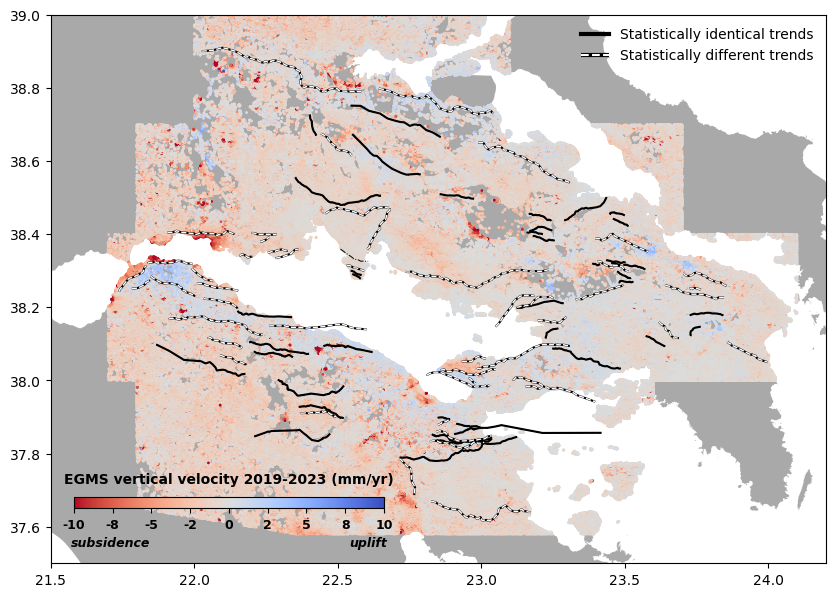

In [18]:
# Create figure - will take a ca. 25s to run 

fig, ax = plt.subplots(figsize=(10, 10))
greece.plot(ax=ax, color='darkgrey')
sm_faults_gdf.plot(ax=ax, color='k', linewidth=0.7, linestyle='-.', label='Faults', zorder=2)

ax.set_xlim([21.5, 24.2])
ax.set_ylim([37.5, 39])
ax.set_aspect('equal')

# Plot faults with significant p-values in black and dashed white lines, and others in black solid lines
for f in faults:
    fault_line = sm_faults_gdf[sm_faults_gdf['Name'] == f]
    if p_values[faults.index(f)] < 0.05:
        fault_line.plot(ax=ax, color='k', linestyle='-', linewidth=1.5, zorder=3)
        fault_line.plot(ax=ax, color='white', linestyle='--', linewidth=1, zorder=4)
    else:
        fault_line.plot(ax=ax, color='k', linestyle='-', linewidth=1.5, zorder=3)

# Plot EGMS data as a scatter plot with color representing mean velocity
cmap = 'coolwarm_r'
norm = plt.Normalize(vmin=-10, vmax=10)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)

ax.scatter(egms_combined['longitude'], egms_combined['latitude'], c=egms_combined['mean_velocity'], s=1, \
    cmap = cmap, norm=norm, label='EGMS 2019-2023', zorder=1)

# Add custom legend for locked and unlocked faults
significant_handle = Line2D([], [], color="black", linestyle="-", linewidth=3)
black_white_handle = Line2D([], [], color="white", linestyle="--", linewidth=1.5) # this is just a placeholder; 
                                                                                  # the actual dashed line will be drawn by the custom handler
ax.legend(
    handles=[significant_handle, black_white_handle],
    labels=["Statistically identical trends", "Statistically different trends"],
    handler_map={black_white_handle: HandlerBlackWhiteDashed()},
    loc="best", facecolor = 'none', frameon = False
)

# Add colorbar for the EGMS scatter plot
cax = ax.inset_axes([0.03, 0.1, 0.4, 0.02])  # [left, bottom, width, height]
cbar = plt.colorbar(sm, cax=cax, orientation='horizontal')
ticks = np.linspace(-10, 10, 9)
cbar.set_ticks(ticks)
cbar.set_ticklabels([f'{tick:.0f}' for tick in ticks], fontsize=9, fontweight='bold')
cbar.set_label('EGMS vertical velocity 2019-2023 (mm/yr)', rotation=0, labelpad=10, fontsize=10, fontweight='bold')
cbar.ax.xaxis.set_label_position('top')
cax.text(-0.01, -3.7, 'subsidence', transform=cax.transAxes, fontsize=9, fontstyle="italic", fontweight='bold', va="bottom", ha="left")
cax.text(1.01, -3.7, 'uplift', transform=cax.transAxes, fontsize=9, fontstyle="italic", fontweight='bold', va="bottom", ha="right")

plt.savefig('figures/faults_egms_plot.png', dpi=300, bbox_inches='tight', transparent=True) 